# S03-01 — RQ01 e RQ02: estatística descritiva (#167)

Frequência de deploy (RQ01) e lead time (RQ02) dos 255 repositórios da amostra encerrada.

- Fonte: `entregas/s02-03-dataset-153/dataset-255.csv` (contrato `lab03-dataset-v1`, janela de 2025-10-01 a 2026-10-01, exclusivo).
- Cada métrica é resumida só pelos valores válidos. Ausências não viram zero e o `n` de cada métrica aparece nas tabelas.
- Quartis por interpolação linear (padrão do pandas); IQR = Q3 − Q1.
- Saídas: `tabelas/` (CSV) e `figuras/` (PNG). Reexecute com *Run All* a partir desta pasta.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAIZ = Path.cwd().parent
sys.path.insert(0, str(RAIZ))
from pipeline.classificacao import DIA, MES, SEMANA
from pipeline.descritiva import SEMANAS_POR_MES, carregar_dataset, comparar_variantes, pares_lead_time, tabela_resumo

DATASET = RAIZ / "entregas" / "s02-03-dataset-153" / "dataset-255.csv"
FIGURAS, TABELAS = Path("figuras"), Path("tabelas")
FIGURAS.mkdir(exist_ok=True)
TABELAS.mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 150, "savefig.dpi": 300, "savefig.bbox": "tight", "font.size": 9,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#dddddd", "grid.linewidth": 0.6, "axes.axisbelow": True,
})
TINTA, TINTA_CLARA, CORTE = "#333333", "#999999", "#777777"

dados = carregar_dataset(DATASET)
pd.options.display.float_format = "{:,.3f}".format
print(f"{len(dados)} repositórios; janela {dados.janela_inicio.iloc[0]} a {dados.janela_fim_exclusivo.iloc[0]}")

255 repositórios; janela 2025-10-01T00:00:00Z a 2026-10-01T00:00:00Z


## RQ01 — Frequência de deploy

DF = releases estáveis na janela / semanas reais da janela. A coluna em releases/mês só reescala a DF (× 365,25/7/12 ≈ 4,35) para comparar com a hipótese de uma a três releases por mês.

In [2]:
dados["df_mes"] = dados["deployment_frequency"] * SEMANAS_POR_MES
rq01 = tabela_resumo(dados, {
    "DF (releases/semana)": "deployment_frequency",
    "DF (releases/mês)": "df_mes",
})
rq01.to_csv(TABELAS / "rq01_resumo.csv", index=False)
rq01

,metrica,n,ausentes,minimo,q1,mediana,q3,iqr,maximo,media
0,DF (releases/semana),255,0,0.096,0.249,0.537,1.199,0.949,49.556,1.417
1,DF (releases/mês),255,0,0.417,1.084,2.335,5.212,4.128,215.481,6.163


In [3]:
df_mes = dados["df_mes"].dropna()
faixas = pd.Series({
    "< 1 release/mês": (df_mes < 1).sum(),
    "1 a 3 releases/mês": df_mes.between(1, 3).sum(),
    "> 3 releases/mês": (df_mes > 3).sum(),
}, name="repositorios").to_frame()
faixas["percentual"] = 100 * faixas["repositorios"] / len(df_mes)
faixas.to_csv(TABELAS / "rq01_faixas_mensais.csv")
faixas

,repositorios,percentual
< 1 release/mês,55,21.569
1 a 3 releases/mês,89,34.902
> 3 releases/mês,111,43.529


C:\Users\Jonathan\AppData\Local\Temp\ipykernel_9300\737410631.py:6: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax_box.boxplot(df, vert=False, widths=0.6, showfliers=True,


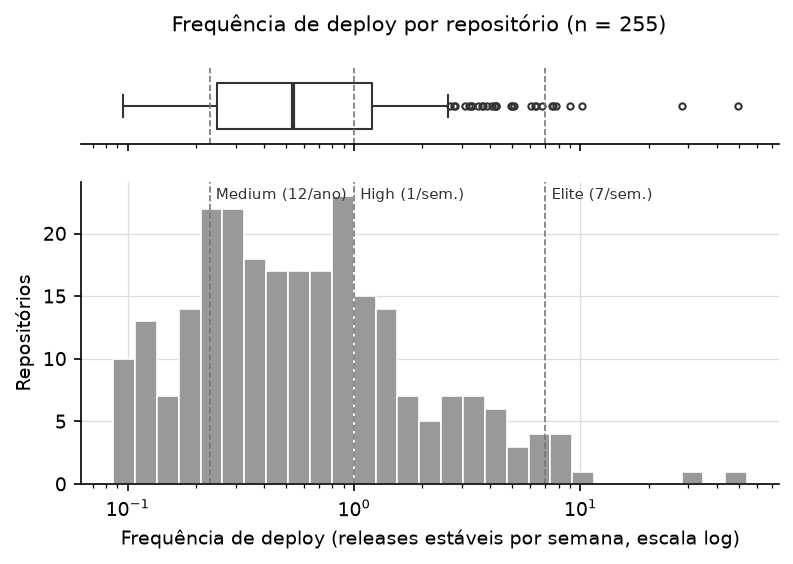

In [4]:
df = dados["deployment_frequency"].dropna()
cortes_df = {"Medium (12/ano)": 12 * 7 / 365, "High (1/sem.)": 1, "Elite (7/sem.)": 7}
bins = np.logspace(np.log10(df.min() * 0.9), np.log10(df.max() * 1.1), 30)

fig, (ax_box, ax_hist) = plt.subplots(2, 1, sharex=True, figsize=(6, 3.6), height_ratios=[1, 4])
ax_box.boxplot(df, vert=False, widths=0.6, showfliers=True,
               flierprops={"marker": "o", "markersize": 3, "markerfacecolor": "none", "markeredgecolor": TINTA},
               medianprops={"color": TINTA, "linewidth": 2}, boxprops={"color": TINTA}, whiskerprops={"color": TINTA},
               capprops={"color": TINTA})
ax_box.set_yticks([])
ax_box.grid(False)
ax_box.spines["left"].set_visible(False)
ax_hist.hist(df, bins=bins, color=TINTA_CLARA, edgecolor="white", linewidth=0.8)
for rotulo, x in cortes_df.items():
    for ax in (ax_box, ax_hist):
        ax.axvline(x, color=CORTE, linestyle="--", linewidth=0.8)
    ax_hist.annotate(rotulo, (x, 1), xycoords=("data", "axes fraction"), xytext=(3, -3),
                     textcoords="offset points", va="top", fontsize=7, color=TINTA)
ax_hist.set_xscale("log")
ax_hist.set_xlabel("Frequência de deploy (releases estáveis por semana, escala log)")
ax_hist.set_ylabel("Repositórios")
fig.suptitle(f"Frequência de deploy por repositório (n = {len(df)})", fontsize=10)
fig.savefig(FIGURAS / "rq01_frequencia_deploy.png")
plt.show()

## RQ02 — Lead time

Variante (a): mediana, por release, de publicação − commit mais antigo. Variante (b): mediana de todos os pares commit–release. Ambas em horas.

**Atenção:** só há compare válido para poucos repositórios (o `n` está na tabela). O resumo descreve esse subconjunto e não generaliza para os 255.

In [5]:
for variante in ("a", "b"):
    dados[f"lead_time_{variante}_dias"] = dados[f"lead_time_{variante}"] / DIA
rq02 = tabela_resumo(dados, {
    "Lead time (a), horas": "lead_time_a",
    "Lead time (b), horas": "lead_time_b",
    "Lead time (a), dias": "lead_time_a_dias",
    "Lead time (b), dias": "lead_time_b_dias",
})
rq02.to_csv(TABELAS / "rq02_resumo.csv", index=False)
rq02

,metrica,n,ausentes,minimo,q1,mediana,q3,iqr,maximo,media
0,"Lead time (a), horas",9,246,4.727,219.611,849.352,"1,774.586","1,554.976","2,904.923","1,053.460"
1,"Lead time (b), horas",9,246,124.879,168.214,582.424,720.162,551.948,"3,299.330",766.281
2,"Lead time (a), dias",9,246,0.197,9.150,35.390,73.941,64.791,121.038,43.894
3,"Lead time (b), dias",9,246,5.203,7.009,24.268,30.007,22.998,137.472,31.928


### Comparação das variantes (a) e (b)

Pares do mesmo repositório. Diferença = (a) − (b), em horas; razão = (a) / (b). A hipótese da RQ02 espera (a) > (b).

In [6]:
pares = pares_lead_time(dados)
pares.to_csv(TABELAS / "rq02_pares_variantes.csv", index=False)
comparacao = pd.Series(comparar_variantes(pares), name="valor", dtype=object).to_frame()
comparacao.to_csv(TABELAS / "rq02_comparacao_variantes.csv")
display(pares)
comparacao

,id,full_name,lead_time_a,lead_time_b,diferenca,razao
0,576201,mrdoob/three.js,"1,774.586",836.390,938.196,2.122
1,612230,nvm-sh/nvm,"2,904.923",588.534,"2,316.388",4.936
2,16408992,neovim/neovim,"1,793.500","3,299.330","-1,505.830",0.544
3,214587193,supabase/supabase,692.339,582.424,109.915,1.189
4,787076358,firecrawl/firecrawl,849.352,429.325,420.027,1.978
5,890668799,modelcontextprotocol/servers,"1,155.120",720.162,434.958,1.604
6,1148788086,mattpocock/skills,4.727,147.272,-142.545,0.032
7,1165277268,Panniantong/Agent-Reach,86.981,124.879,-37.898,0.697
8,1182081931,Egonex-AI/Understand-Anything,219.611,168.214,51.396,1.306


,valor
n_pares,9
a_maior,6
iguais,0
a_menor,3
mediana_diferenca,109.915
mediana_razao,1.306


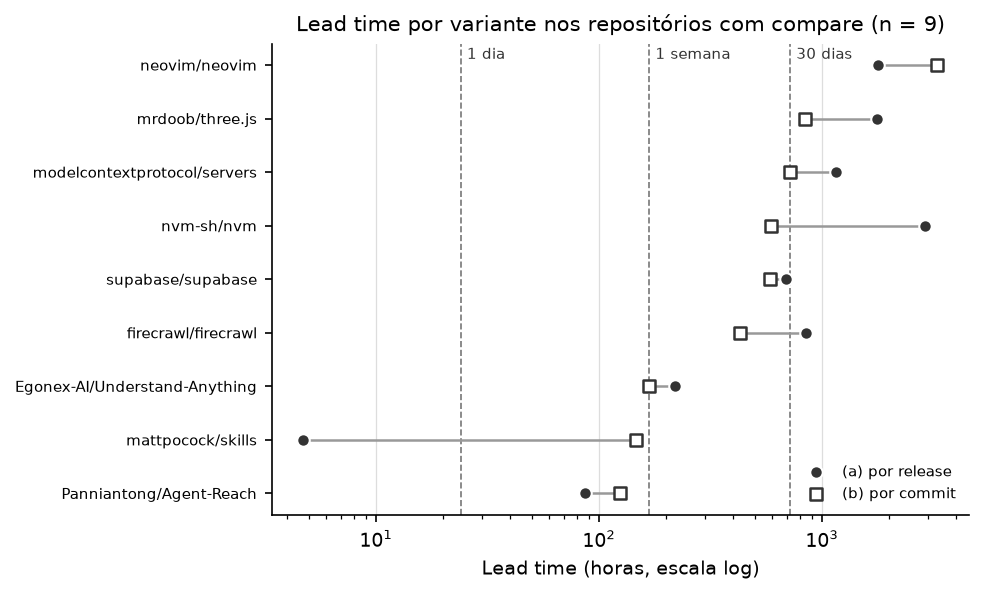

In [7]:
ordem = pares.sort_values("lead_time_b").reset_index(drop=True)
y = np.arange(len(ordem))
cortes_lt = {"1 dia": DIA, "1 semana": SEMANA, "30 dias": MES}

fig, ax = plt.subplots(figsize=(6, 0.32 * len(ordem) + 1.2))
for i, linha in ordem.iterrows():
    ax.plot([linha.lead_time_a, linha.lead_time_b], [i, i], color=TINTA_CLARA, linewidth=1.2, zorder=1)
ax.scatter(ordem.lead_time_a, y, marker="o", s=36, color=TINTA, edgecolor="white", linewidth=1, zorder=2,
           label="(a) por release")
ax.scatter(ordem.lead_time_b, y, marker="s", s=36, color="white", edgecolor=TINTA, linewidth=1.2, zorder=2,
           label="(b) por commit")
for rotulo, x in cortes_lt.items():
    ax.axvline(x, color=CORTE, linestyle="--", linewidth=0.8, zorder=0)
    ax.annotate(rotulo, (x, 1), xycoords=("data", "axes fraction"), xytext=(3, -2),
                textcoords="offset points", va="top", fontsize=7, color=TINTA)
ax.set_yticks(y, ordem.full_name, fontsize=7)
ax.set_xscale("log")
ax.set_xlabel("Lead time (horas, escala log)")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right", fontsize=7, frameon=False)
ax.set_title(f"Lead time por variante nos repositórios com compare (n = {len(ordem)})", fontsize=10)
fig.savefig(FIGURAS / "rq02_lead_time_variantes.png")
plt.show()

## Limitações

- O lead time depende do compare entre releases, disponível só para o subconjunto acima. Os demais repositórios têm `lead_time_a`/`lead_time_b` nulos e `coleta_incompleta=true`; o resultado da RQ02 é exploratório.
- A população encerrada não corresponde aos 255 primeiros por estrelas (ver `funil.md` da #153), o que limita a generalização.
- A classificação DORA das métricas fica na S03-03 (#169).